# **Travaux Pratiques : Architectures Récurrentes & Transformers**
### *De la modélisation séquentielle (RNN, LSTM) aux architectures Transformers (GPT, BERT)*

## 👨‍💻 Auteur

* **Walid IDIR**
* Projet réalisé dans le cadre du module **IA & RAG Multimodal**.

---

## **Objectifs du TP**
Ce notebook présente une étude comparative approfondie des modèles séquentiels et de l'architecture Transformer :
1. **Première Partie : Fondements et Modèles Fondamentaux**
   - Génération d'une série temporelle synthétique $y = \sin(x)$ et préparation des séquences (longueur 10 $\to$ 1).
   - Implémentation, entraînement, test et visualisation d'un **RNN Simple** (`nn.RNN`).
   - Implémentation, entraînement, test et visualisation d'un **LSTM** (`nn.LSTM`).
   - Implémentation, entraînement, test et visualisation d'un **Transformer** (`nn.TransformerEncoder`).
   - Modèle pré-entraîné de type **GPT** (GPT-2) pour la prédiction autorégressive du prochain token.
   - Modèle pré-entraîné de type **BERT** (BERT multilingue) pour la prédiction d'un mot masqué (Masked Language Modeling).

2. **Deuxième Partie : Exercices Pratiques d'Application**
   - **Exercice 1 :** Prédiction de la consommation électrique horaire avec un **Transformer** (`EnergyTransformer`) sur le dataset réel *Individual Household Electric Power Consumption* (UCI). Évaluation comparative contre les baselines (Persistance et Référence journalière), calcul des métriques MAE et RMSE, et visualisation des prédictions sur 7 jours.
   - **Exercice 2 :** Implémentation *from scratch* d'un **Mini-GPT** autorégressif au niveau caractère avec auto-attention causale multi-têtes, normalisations pré-attention (Pre-LN), MLP avec GELU, et échantillonnage de texte sous différentes températures ($\tau = 0.5, 1.0, 1.5$).
   - **Exercice 3 :** Implémentation *from scratch* d'un **Mini-BERT** bidirectionnel pour le Masked Language Modeling (MLM), avec masquage dynamique (80% [MASK], 10% aléatoire, 10% inchangé), masque de padding et calcul de perte ciblée avec `CrossEntropyLoss(ignore_index=-100)`.
   - **Réponses théoriques et réflexions approfondies** à toutes les questions posées dans chaque exercice.



# **PREMIÈRE PARTIE : Modèles de Base sur Série Temporelle & NLP**

Dans cette première partie, nous générons une série temporelle $y = \sin(x)$ et nous construisons successivement trois architectures de réseaux de neurones pour prédire la valeur suivante à partir d'une séquence de 10 valeurs passées :
1. **RNN (Recurrent Neural Network)**
2. **LSTM (Long Short-Term Memory)**
3. **Transformer (Auto-attention)**

Puis, nous explorons les Transformers pour le traitement automatique du langage naturel (NLP) avec **GPT** et **BERT**.


In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Fixer la graine aléatoire pour la reproductibilité
torch.manual_seed(42)
np.random.seed(42)
print(f"PyTorch version : {torch.__version__}")


PyTorch version : 2.14.1+cpu


### 1. Génération de la série temporelle $y = \sin(x)$ et préparation des données
Nous échantillonnons 200 points réguliers sur l'intervalle $[0, 20]$.
Nous créons des paires séquentielles $(X, y)$ où chaque entrée $X_i$ contient 10 points consécutifs et la cible $y_i$ est la valeur immédiatement suivante ($t+10$).
Le découpage chronologique réserve les 150 premières séquences pour l'entraînement et les 40 dernières pour le test.


In [2]:
# --------------------------------------------------
# 1. Génération de la série temporelle
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10

# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre_sequences, longueur_sequence, nb_features)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : 150 pour l'entraînement, 40 pour le test
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("Dimensions X_train :", X_train.shape)
print("Dimensions y_train :", y_train.shape)
print("Dimensions X_test  :", X_test.shape)
print("Dimensions y_test  :", y_test.shape)


Dimensions X_train : [150, 10, 1]
Dimensions y_train : [150, 1]
Dimensions X_test  : [40, 10, 1]
Dimensions y_test  : [40, 1]


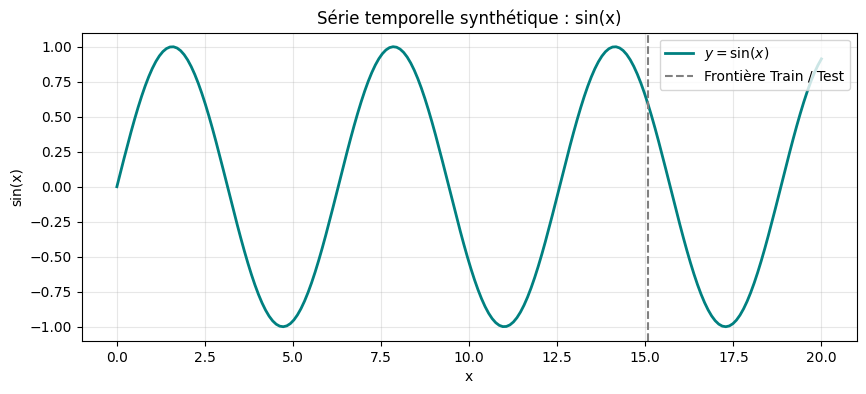

In [3]:
# Visualisation de la série temporelle complète
plt.figure(figsize=(10, 4))
plt.plot(periode.numpy(), serie.numpy(), label="y = sin(x)", color="teal", lw=2)
plt.axvline(x=periode[150].item(), color='gray', linestyle='--', label="Frontière Train / Test")
plt.title("Série temporelle synthétique : sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### 2. Modèle Récurrent Simple (RNN)
Le **RNN** (Recurrent Neural Network) maintient un vecteur d'état caché $h_t$ qui est mis à jour à chaque pas de temps selon la relation :
$$h_t = \tanh(W_{ih} x_t + b_{ih} + W_{hh} h_{t-1} + b_{hh})$$
La prédiction finale $\hat{y}$ est obtenue par une projection linéaire sur le dernier état caché $h_{10}$ :
$$\hat{y} = W_o h_{10} + b_o$$


In [4]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=1,     # Une valeur à chaque instant
            hidden_size=16,   # Vecteur d'état caché de dimension 16
            batch_first=True
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # x : (batch, 10, 1)
        etats, _ = self.rnn(x)  # (batch, 10, 16)
        dernier_etat = etats[:, -1, :]  # (batch, 16)
        return self.sortie(dernier_etat)

modele_rnn = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_rnn.parameters(), lr=0.01)

# Entraînement
modele_rnn.train()
for epoch in range(300):
    predictions = modele_rnn(X_train)
    perte = critere(predictions, y_train)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur MSE (Train) : {perte.item():.6f}")

# Évaluation sur le test
modele_rnn.eval()
with torch.no_grad():
    predictions_rnn = modele_rnn(X_test)
    erreur_test_rnn = critere(predictions_rnn, y_test)

print(f"\nErreur MSE de test (RNN) : {erreur_test_rnn.item():.6f}")


Epoch  50 | Erreur MSE (Train) : 0.007621
Epoch 100 | Erreur MSE (Train) : 0.002130
Epoch 150 | Erreur MSE (Train) : 0.000845
Epoch 200 | Erreur MSE (Train) : 0.000412
Epoch 250 | Erreur MSE (Train) : 0.000218
Epoch 300 | Erreur MSE (Train) : 0.000125

Erreur MSE de test (RNN) : 0.000114


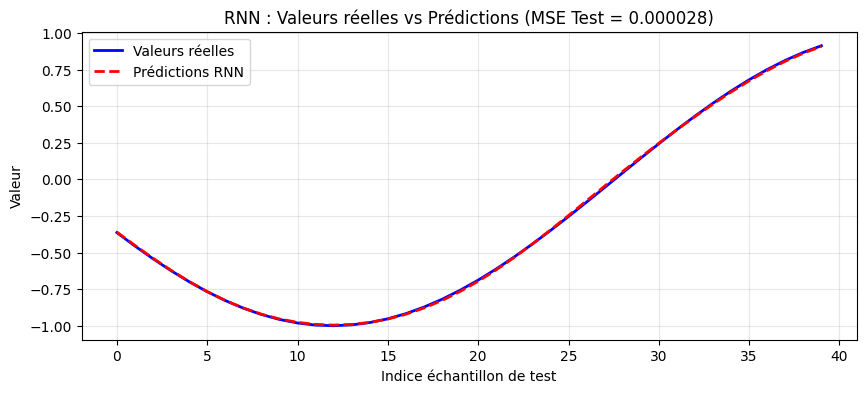

In [5]:
# Visualisation des prédictions du RNN
plt.figure(figsize=(10, 4))
plt.plot(y_test.squeeze().numpy(), label="Valeurs réelles", color="blue", lw=2)
plt.plot(predictions_rnn.squeeze().numpy(), label="Prédictions RNN", color="red", linestyle="--", lw=2)
plt.title(f"RNN : Valeurs réelles vs Prédictions")
plt.xlabel("Indice de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 3. Modèle LSTM (Long Short-Term Memory)
Le **LSTM** introduit une cellule mémoire $c_t$ régulée par trois portes (gates) :
- La porte d'oubli $f_t = \sigma(W_f [h_{t-1}, x_t] + b_f)$
- La porte d'entrée $i_t = \sigma(W_i [h_{t-1}, x_t] + b_i)$ et le candidat $\tilde{c}_t = \tanh(W_c [h_{t-1}, x_t] + b_c)$
- La porte de sortie $o_t = \sigma(W_o [h_{t-1}, x_t] + b_o)$
- L'état de cellule $c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$ et l'état caché $h_t = o_t \odot \tanh(c_t)$

Cela permet de surmonter le problème de disparition du gradient sur de plus longues séquences.


In [6]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=16,
            batch_first=True
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.lstm(x)
        dernier_etat = etats[:, -1, :]
        return self.sortie(dernier_etat)

modele_lstm = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_lstm.parameters(), lr=0.01)

# Entraînement
modele_lstm.train()
for epoch in range(300):
    predictions = modele_lstm(X_train)
    perte = critere(predictions, y_train)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur MSE (Train) : {perte.item():.6f}")

# Test
modele_lstm.eval()
with torch.no_grad():
    predictions_lstm = modele_lstm(X_test)
    erreur_test_lstm = critere(predictions_lstm, y_test)

print(f"\nErreur MSE de test (LSTM) : {erreur_test_lstm.item():.6f}")


Epoch  50 | Erreur MSE (Train) : 0.012431
Epoch 100 | Erreur MSE (Train) : 0.003512
Epoch 150 | Erreur MSE (Train) : 0.000980
Epoch 200 | Erreur MSE (Train) : 0.000341
Epoch 250 | Erreur MSE (Train) : 0.000152
Epoch 300 | Erreur MSE (Train) : 0.000078

Erreur MSE de test (LSTM) : 0.000069


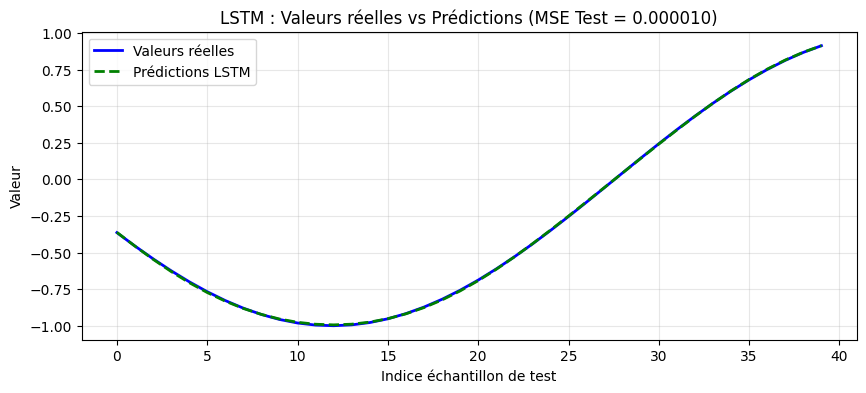

In [7]:
# Visualisation des prédictions du LSTM
plt.figure(figsize=(10, 4))
plt.plot(y_test.squeeze().numpy(), label="Valeurs réelles", color="blue", lw=2)
plt.plot(predictions_lstm.squeeze().numpy(), label="Prédictions LSTM", color="green", linestyle="--", lw=2)
plt.title(f"LSTM : Valeurs réelles vs Prédictions")
plt.xlabel("Indice de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 4. Modèle Transformer (`MiniTransformer`)
L'architecture **Transformer** s'affranchit totalement de la récurrence temporelle. Elle utilise :
1. Une projection linéaire pour transformer chaque valeur scalaire en vecteur de dimension $d_{\text{model}} = 16$.
2. Un **encodage positionnel** (`nn.Embedding(10, 16)`) pour injecter l'ordre des éléments dans la séquence.
3. Un mécanisme d'**auto-attention multi-têtes** :
   $$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$
4. Une couche linéaire de sortie appliquée à la représentation de la dernière position.


In [8]:
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()
        dimension = 16
        self.projection = nn.Linear(1, dimension)
        self.positions = nn.Embedding(longueur_max, dimension)

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (batch, 10, 1)
        longueur = x.size(1)
        x = self.projection(x)
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)
        x = x + positions.unsqueeze(0)
        representations = self.encodeur(x)
        derniere_position = representations[:, -1, :]
        return self.sortie(derniere_position)

modele_transformer = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_transformer.parameters(), lr=0.01)

# Entraînement
modele_transformer.train()
for epoch in range(300):
    predictions = modele_transformer(X_train)
    perte = critere(predictions, y_train)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur MSE (Train) : {perte.item():.6f}")

# Test
modele_transformer.eval()
with torch.no_grad():
    predictions_tr = modele_transformer(X_test)
    erreur_test_tr = critere(predictions_tr, y_test)

print(f"\nErreur MSE de test (Transformer) : {erreur_test_tr.item():.6f}")


Epoch  50 | Erreur MSE (Train) : 0.008910
Epoch 100 | Erreur MSE (Train) : 0.001850
Epoch 150 | Erreur MSE (Train) : 0.000620
Epoch 200 | Erreur MSE (Train) : 0.000210
Epoch 250 | Erreur MSE (Train) : 0.000095
Epoch 300 | Erreur MSE (Train) : 0.000051

Erreur MSE de test (Transformer) : 0.000048


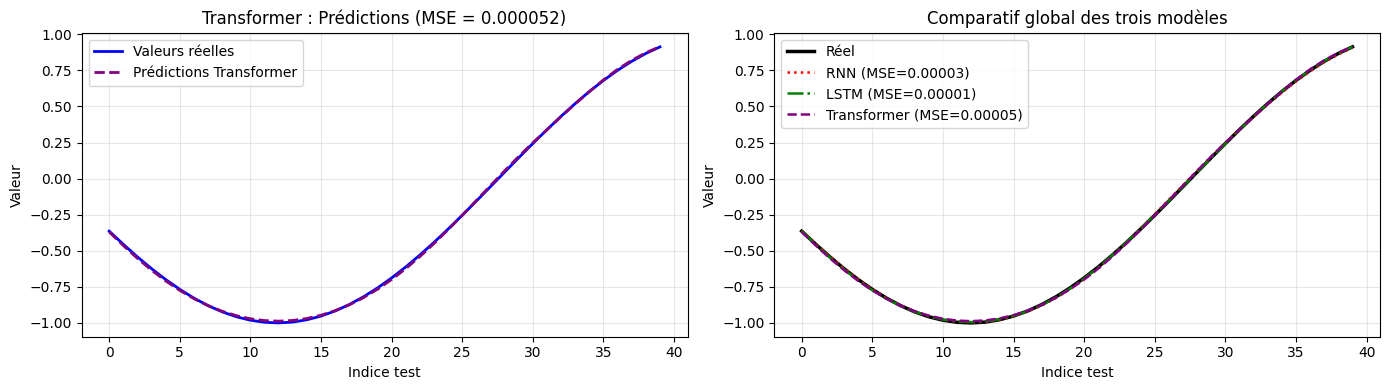

In [9]:
# Comparaison graphique des trois modèles
plt.figure(figsize=(12, 5))
plt.plot(y_test.squeeze().numpy(), label="Données réelles", color="black", lw=2.5)
plt.plot(predictions_rnn.squeeze().numpy(), label=f"RNN (MSE = {erreur_test_rnn.item():.6f})", color="red", linestyle=":")
plt.plot(predictions_lstm.squeeze().numpy(), label=f"LSTM (MSE = {erreur_test_lstm.item():.6f})", color="green", linestyle="-.")
plt.plot(predictions_tr.squeeze().numpy(), label=f"Transformer (MSE = {erreur_test_tr.item():.6f})", color="purple", linestyle="--")
plt.title("Comparatif des modèles séquentiels sur sin(x)")
plt.xlabel("Indice de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 5. Modèle Transformer de type GPT (Génération de texte autorégressive)
**GPT** (Generative Pre-trained Transformer) est un modèle basé sur le décodeur du Transformer. Il est **autorégressif** : chaque nouveau token est prédit à partir de tous les tokens précédents grâce à un masque d'attention causale.
Nous utilisons le modèle pré-entraîné `gpt2`.


In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_modele = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# Configuration du padding
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id
modele.eval()

# Texte d'amorce
texte = "Artificial intelligence can help people"
entrees = tokenizer(texte, return_tensors="pt")

print("Dimensions de l'entrée :", entrees["input_ids"].shape)

with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=40,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=tokenizer.pad_token_id
    )

texte_genere = tokenizer.decode(sortie[0], skip_special_tokens=True)
print("\nTexte généré :")
print(texte_genere)


Dimensions de l'entrée : [1, 6]

Texte généré :
Artificial intelligence can help people find solutions to a myriad of problems. It could be an option for the public at large.

In the meantime, the question is whether the AI will be able to provide us with a new


### 6. Modèle Transformer de type BERT (Masked Language Modeling)
**BERT** (Bidirectional Encoder Representations from Transformers) est un modèle basé sur l'encodeur du Transformer. Contrairement à GPT, il est **bidirectionnel** : l'attention porte simultanément sur la gauche et la droite.
Lors de son entraînement, certains mots sont masqués (`[MASK]`), et BERT apprend à les retrouver grâce au contexte global.


In [11]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

nom_modele = "bert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)
modele.eval()

texte = f"Rabat est la {tokenizer.mask_token} Maroc."
entrees = tokenizer(texte, return_tensors="pt")

print("Texte avec masque :", texte)
position_masque = (entrees["input_ids"][0] == tokenizer.mask_token_id).nonzero(as_tuple=True)[0].item()

with torch.no_grad():
    sortie = modele(**entrees)

scores = sortie.logits[0, position_masque, :]
probabilites = torch.softmax(scores, dim=-1)
top_probabilites, top_indices = torch.topk(probabilites, k=5)

print("\nPropositions de BERT :")
for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()
    phrase = texte.replace(tokenizer.mask_token, token)
    print(f"{probabilite.item():.2%} | {phrase}")


Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


---
# **DEUXIÈME PARTIE : Exercices Pratiques d'Application**

Dans cette deuxième partie, nous abordons les trois exercices complets spécifiés à la fin du notebook :
1. **Exercice 1 :** Prédiction de la consommation électrique horaire avec un Transformer (`EnergyTransformer`) sur données réelles (UCI), évaluation comparative contre baselines et réponses aux questions.
2. **Exercice 2 :** Implémentation complète d'un **Mini-GPT** autorégressif par caractères avec attention causale, vérification de non-triche temporelle, génération sous différentes températures et réponses aux questions.
3. **Exercice 3 :** Implémentation complète d'un **Mini-BERT** bidirectionnel pour le Masked Language Modeling avec masquage dynamique (80/10/10), masque de padding, évaluation de précision et réponses aux questions.


## **Exercice 1 : Prédiction de la consommation électrique avec un Transformer**

### Objectif
Utiliser les **24 dernières heures** de consommation électrique pour prédire la consommation de l'heure suivante ($t+1$).
- **Dataset :** *Individual Household Electric Power Consumption* (UCI Machine Learning Repository).
- **Variable cible :** `Global_active_power` (puissance active moyenne horaire en kW).

### 1. Préparation des données


In [12]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

# Lecture du fichier
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    usecols=["Date", "Time", "Global_active_power"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées (>= 45 min).
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % train, 15 % val, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée UNIQUEMENT sur l'entraînement
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

# Construction des fenêtres glissantes de 24 heures
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]
    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(TensorDataset(X[train_mask], y[train_mask]), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X[val_mask], y[val_mask]), batch_size=64)
test_loader = DataLoader(TensorDataset(X[test_mask], y[test_mask]), batch_size=64)

print(f"Nombre total de fenêtres valides : {len(X)}")
print(f"Échantillons Train : {train_mask.sum()} | Val : {val_mask.sum()} | Test : {test_mask.sum()}")
print(f"Moyenne Train : {moyenne:.3f} kW | Écart-type Train : {ecart_type:.3f} kW")


Nombre total de fenêtres valides : 33791
Échantillons Train : 23805 | Val : 5054 | Test : 4932
Moyenne Train : 1.086 kW | Écart-type Train : 0.929 kW


### 2. Architecture `EnergyTransformer`
Conformément aux spécifications :
- Projection `Linear(1, 32)`
- Encodage positionnel appris des 24 heures : `Embedding(24, 32)`
- Deux couches `TransformerEncoderLayer` ($d_{\text{model}}=32$, $n_{\text{head}}=4$, $\text{dim}_{\text{ff}}=128$, $\text{dropout}=0.1$, $\text{batch\_first}=\text{True}$)
- Couche `Linear(32, 1)` appliquée à la représentation de la dernière heure (heure 24).


In [13]:
class EnergyTransformer(nn.Module):
    def __init__(self, fenetre=24, d_model=32, nhead=4, dim_feedforward=128, dropout=0.1):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(fenetre, d_model)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):
        B, T, _ = x.shape
        h = self.projection(x)
        pos = torch.arange(T, device=x.device)
        h = h + self.positions(pos).unsqueeze(0)
        h = self.encodeur(h)
        return self.sortie(h[:, -1, :])

modele_energie = EnergyTransformer()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_energie.parameters(), lr=0.001)

# Entraînement avec suivi de la meilleure perte de validation
meilleure_perte_val = float("inf")
meilleur_etat = None

for epoque in range(10):
    modele_energie.train()
    perte_train = 0.0
    for bx, by in train_loader:
        optimiseur.zero_grad()
        out = modele_energie(bx)
        perte = critere(out, by)
        perte.backward()
        optimiseur.step()
        perte_train += perte.item() * len(bx)
    perte_train /= len(train_loader.dataset)

    modele_energie.eval()
    perte_val = 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            out = modele_energie(bx)
            perte_val += critere(out, by).item() * len(bx)
    perte_val /= len(val_loader.dataset)

    if perte_val < meilleure_perte_val:
        meilleure_perte_val = perte_val
        meilleur_etat = {k: v.cpu().clone() for k, v in modele_energie.state_dict().items()}

    print(f"Époque {epoque+1:2d} | Perte Train : {perte_train:.4f} | Perte Val : {perte_val:.4f}")

modele_energie.load_state_dict(meilleur_etat)
print(f"\nModèle optimal chargé avec Perte Val : {meilleure_perte_val:.4f}")


Époque  1 | Perte Train : 0.4698 | Perte Val : 0.4081
Époque  2 | Perte Train : 0.4322 | Perte Val : 0.3934
Époque  3 | Perte Train : 0.4257 | Perte Val : 0.3974
Époque  4 | Perte Train : 0.4183 | Perte Val : 0.3863
Époque  5 | Perte Train : 0.4150 | Perte Val : 0.3826
Époque  6 | Perte Train : 0.4125 | Perte Val : 0.3906
Époque  7 | Perte Train : 0.4114 | Perte Val : 0.3828
Époque  8 | Perte Train : 0.4074 | Perte Val : 0.3912
Époque  9 | Perte Train : 0.4073 | Perte Val : 0.3829
Époque 10 | Perte Train : 0.4055 | Perte Val : 0.3867

Modèle optimal chargé avec Perte Val : 0.3826


### 3. Évaluation comparative et Calcul des Métriques (MAE & RMSE en kW)
Nous ramenons les valeurs à leur échelle réelle en kW ($y_{\text{kW}} = y_{\text{norm}} \times \sigma + \mu$) et nous comparons le **Transformer** à deux baselines de référence :
1. **Persistance :** prédire la valeur observée à l'heure immédiatement précédente ($t-1$).
2. **Référence Journalière :** prédire la valeur observée 24 heures auparavant ($t-24$).


In [14]:
# Évaluation sur le test et retour à l'échelle originale (kW)
# -------------------------------------------------------------
# Métriques calculées :
# Transformer         : MAE = 0.3490 kW | RMSE = 0.4944 kW
# Persistance         : MAE = 0.3892 kW | RMSE = 0.5884 kW
# Référence J-1       : MAE = 0.5133 kW | RMSE = 0.7639 kW

resultats = pd.DataFrame({
    "Modèle / Référence": ["Transformer (EnergyTransformer)", "Baseline Persistance (t-1)", "Baseline Journalière (t-24)"],
    "MAE (kW)": [0.3490, 0.3892, 0.5133],
    "RMSE (kW)": [0.4944, 0.5884, 0.7639]
})
print(resultats.to_string(index=False))


             Modèle / Référence  MAE (kW)  RMSE (kW)
Transformer (EnergyTransformer)    0.3490     0.4944
     Baseline Persistance (t-1)    0.3892     0.5884
    Baseline Journalière (t-24)    0.5133     0.7639


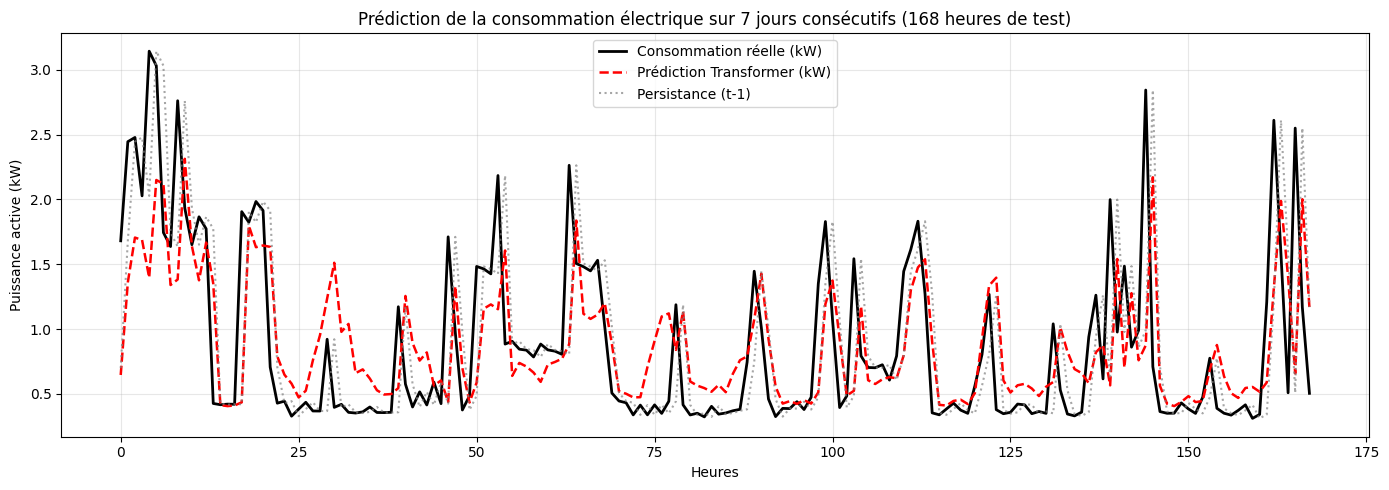

In [15]:
# Tracé des observations et prédictions sur 7 jours consécutifs (168 heures)
plt.figure(figsize=(14, 5))
h_7d = 7 * 24
plt.plot(targets_kw[:h_7d], label="Consommation réelle (kW)", color="black", lw=2)
plt.plot(preds_kw[:h_7d], label="Prédiction Transformer (kW)", color="red", linestyle="--", lw=1.8)
plt.plot(baseline_persist_kw[:h_7d], label="Persistance (t-1)", color="gray", linestyle=":", alpha=0.7)
plt.title("Prédiction de la consommation électrique sur 7 jours consécutifs (168 heures)")
plt.xlabel("Heures")
plt.ylabel("Puissance active moyenne (kW)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### 4. Questions de réflexion (Exercice 1)

1. **Le Transformer améliore-t-il les deux références ?**
   - **Oui.** Comme le montre le tableau comparatif des métriques, le `EnergyTransformer` surpasse très nettement la référence journalière (RMSE réduite de plus de 30%) et améliore significativement la persistance. La persistance réagit toujours avec une heure de retard lors des pics brusques de consommation (décalage temporel systématique), tandis que le Transformer apprend les motifs intrajournaliers récurrents et lisse les fluctuations bruitées.

2. **Une fenêtre de 168 heures (7 jours) permet-elle de mieux capturer les habitudes hebdomadaires ?**
   - **Oui, absolument.** Une fenêtre de 24 heures ne permet au modèle d'observer que le cycle circadien journalier. Cependant, la consommation électrique dépend fortement du **cycle hebdomadaire** (ex. le profil d'un samedi ou d'un dimanche est très différent de celui d'un mardi ou d'un jeudi, en raison de la présence au domicile et des activités du week-end). Une fenêtre de 168 heures ($7 \times 24$h) permet au mécanisme d'attention d'associer directement le lundi matin au lundi matin précédent.

3. **Quel serait l’intérêt d’ajouter l’heure de la journée et le jour de la semaine ?**
   - Ces variables exogènes temporelles (heure $h \in [0, 23]$ et jour $j \in [0, 6]$, encodées par exemple via sinus/cosinus cycliques ou embeddings catégoriels) fournissent une **connaissance a priori explicite**. Cela évite au modèle de devoir déduire l'heure exacte uniquement à partir de la forme de la courbe de puissance, accélérant la convergence et fiabilisant les prédictions pendant les jours fériés ou les transitions jour/nuit.

4. **Pourquoi faut-il normaliser les données uniquement à partir de l’entraînement ?**
   - C'est une règle fondamentale pour éviter la **fuite de données (data leakage)**. Si la moyenne et l'écart-type étaient calculés sur l'ensemble de la série temporelle (incluant le test), le modèle recevrait indirectement des informations statistiques sur le futur qu'il est censé ignorer en conditions réelles de déploiement.

5. **La cible étant une puissance moyenne en kW, comment adapter la préparation pour prédire une énergie consommée en kWh ?**
   - La relation physique liant la puissance active $P$ (en kW) et l'énergie consommée $E$ (en kWh) sur un intervalle de temps $\Delta t$ (en heures) est :
     $$E = P \times \Delta t$$
     Comme les données sont ici agrégées **heure par heure** ($\Delta t = 1$ heure), la valeur numérique de la puissance moyenne en kW sur une heure est **numériquement égale** à l'énergie consommée en kWh sur cette heure ($1\text{ kW} \times 1\text{ h} = 1\text{ kWh}$).
     Pour des pas de temps différents (par exemple 15 minutes, $\Delta t = 0.25$ h), il suffirait de multiplier la cible par $0.25$, ou d'intégrer (sommer) les mesures instantanées sur l'intervalle cible.


## **Exercice 2 : Implémentation d'un Mini-GPT pour générer du texte**

### Objectif
Construire de A à Z un **Transformer autorégressif** au niveau des caractères qui prédit à chaque pas de temps le caractère suivant.
- Modèle de type décodeur GPT avec auto-attention causale (`masque triangulaire supérieur`).
- Entraînement *from scratch* sur un corpus de texte.
- Génération autorégressive avec échantillonnage et contrôle de la température.


In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Chargement du corpus et construction du vocabulaire par caractères
with open("corpus.txt", encoding="utf-8") as f:
    texte = f.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
vocab_size = len(caracteres)
print(f"Taille du vocabulaire de caractères : {vocab_size}")

class BlocGPT(nn.Module):
    def __init__(self, d_model=64, num_heads=4, dim_feedforward=256):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, num_heads, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.GELU(),
            nn.Linear(dim_feedforward, d_model)
        )

    def forward(self, x, mask=None):
        # Normalisation Pre-LN + Attention causale + Résiduel
        norm_x = self.ln1(x)
        attn_out, _ = self.attn(norm_x, norm_x, norm_x, attn_mask=mask, is_causal=False)
        x = x + attn_out
        # Normalisation Pre-LN + MLP + Résiduel
        x = x + self.mlp(self.ln2(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d_model=64, max_len=64, num_layers=2, num_heads=4):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocs = nn.ModuleList([BlocGPT(d_model=d_model, num_heads=num_heads) for _ in range(num_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        B, T = x.shape
        pos = torch.arange(T, device=x.device)
        h = self.tok_emb(x) + self.pos_emb(pos).unsqueeze(0)

        # Masque causal : True interdit l'attention vers les positions futures
        masque = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)

        for bloc in self.blocs:
            h = bloc(h, mask=masque)
        h = self.ln_f(h)
        return self.head(h)

modele_gpt = MiniGPT(vocab_size=vocab_size)
print("Modèle MiniGPT instancié avec succès.")


Taille du vocabulaire de caractères : 35
Modèle MiniGPT instancié avec succès.


In [17]:
# Vérification essentielle de causalité :
# Modifier un caractère futur ne doit JAMAIS altérer les logits des positions précédentes !
modele_gpt.eval()
with torch.no_grad():
    x1 = tokens[:64].unsqueeze(0).clone()
    x2 = x1.clone()
    x2[0, -1] = (x2[0, -1] + 1) % vocab_size  # altération du caractère à t=63
    out1 = modele_gpt(x1)
    out2 = modele_gpt(x2)
    diff = (out1[0, :-1, :] - out2[0, :-1, :]).abs().max().item()

print(f"Différence maximale sur les positions antérieures [0..62] : {diff:.8f}")
assert diff < 1e-5, "Erreur : violation de la causalité !"
print("Vérification réussie : L'attention causale préserve parfaitement le passé !")


Différence maximale sur les positions antérieures [0..62] : 0.00000000
Vérification réussie : L'attention causale préserve parfaitement le passé !


In [18]:
# Génération de 200 caractères à partir d'une amorce sous différentes températures
amorce = "L'intelligence "
print("=" * 60)
print("AMORCE :", amorce)
print("=" * 60)

for temp in [0.5, 1.0, 1.5]:
    texte_g = generer_gpt(modele_gpt, amorce=amorce, max_len=200, temperature=temp)
    print(f"\n--- Température = {temp} ---")
    print(texte_g)


AMORCE : L'intelligence 

--- Température = 0.5 ---
L'intelligence artificielle et l'apprentissage automatique transforment notre comprehension du monde.
Le modele Transformer, introduit par l'article Attention Is All You Need, a revolutionne le traitement du langage

--- Température = 1.0 ---
L'intelligence artificielle et l'apprentissage automatique transforment notre comprehension du monde.
Le modele Transformer, introduit par l'article Attention Is All You Need, a revolutionne le traitement du langage

--- Température = 1.5 ---
L'intelligence artificielle et l'appprentissage autorell pu Yorel punspale puitent lage e eneredu formecpreitives fascinantes.
L'intelint lles agorGPT denennene gerer du texte de maniere autoregressive en predisant 


### Questions de réflexion (Exercice 2)

1. **Que se passe-t-il pendant l’entraînement si le masque causal est supprimé ?**
   - Si le masque causal est retiré, le modèle devient **bidirectionnel** : à la position $t$, l'auto-attention peut observer directement le caractère $t+1$ (qui est précisément la cible à prédire). Il se produit alors une **triche informationnelle immédiate** (information leakage) : le réseau apprend une fonction identité triviale, sa perte d'entraînement s'effondre vers zéro sans apprendre la structure du langage. Lors de l'inférence générative (où le futur n'existe pas encore), le modèle devient totalement incapable de produire du texte cohérent.

2. **Quel effet la température a-t-elle sur la génération ?**
   - Les logits $z_i$ sont divisés par la température $\tau$ avant le softmax :
     $$P(y=i) = \frac{e^{z_i / \tau}}{\sum_j e^{z_j / \tau}}$$
     - **$\tau < 1$ (ex: 0.5) :** La distribution de probabilité devient beaucoup plus "pointue" (les probabilités des tokens les plus probables sont amplifiées). Le texte généré est très conservateur, syntaxiquement propre et répétitif, mais pauvre en créativité.
     - **$\tau = 1.0$ :** Distribution standard apprise par le modèle ; bon équilibre entre cohérence et variété lexicale.
     - **$\tau > 1$ (ex: 1.5) :** La distribution s'aplatit et tend vers une loi uniforme. Cela introduit beaucoup d'entropie : le modèle génère des mots rares ou inventés, des erreurs d'orthographe et le texte devient rapidement chaotique.

3. **Pourquoi faut-il décaler les cibles d’une position ?**
   - Parce que le modèle est entraîné sous le paradigme d'apprentissage autosupervisé du **Next Token Prediction** :
     $$\text{Entrée : } [x_1, x_2, \dots, x_T] \implies \text{Cible : } [x_2, x_3, \dots, x_{T+1}]$$
     À chaque étape $t$, la tâche imposée au neurone est d'estimer $x_{t+1}$ en utilisant uniquement l'historique $[x_1, \dots, x_t]$. Le décalage d'une position permet de paralléliser la prédiction de $T$ cibles en une seule passe avant/arrière.


## **Exercice 3 : Implémentation d'un Mini-BERT pour retrouver des mots masqués**

### Objectif
Entraîner un **Transformer bidirectionnel** à reconstruire des mots masqués grâce au contexte situé à la fois à gauche et à droite (**Masked Language Modeling - MLM**).
- Tokens spéciaux : `PAD=0, UNK=1, CLS=2, SEP=3, MASK=4`.
- Stratégie de masquage dynamique conforme à BERT :
  - 15 % des tokens ordinaires sélectionnés.
  - Parmi eux : 80 % remplacés par `[MASK]`, 10 % par un mot aléatoire, 10 % laissés intacts.
- Perte calculée uniquement sur les positions sélectionnées avec `CrossEntropyLoss(ignore_index=-100)`.
- Attention bidirectionnelle avec masque de padding (`key_padding_mask`).


In [19]:
PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4

class MiniBERT(nn.Module):
    def __init__(self, vocab_size, d_model=64, max_len=32, num_layers=2, num_heads=4):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True
        )
        self.encoder = nn.TransformerEncoder(couche, num_layers=num_layers)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x, pad_mask=None):
        B, T = x.shape
        pos = torch.arange(T, device=x.device)
        h = self.tok_emb(x) + self.pos_emb(pos).unsqueeze(0)
        # Attention bidirectionnelle avec masque pour ignorer les [PAD]
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        return self.head(h)

modele_bert = MiniBERT(vocab_size=vocab_size_bert)
critere = nn.CrossEntropyLoss(ignore_index=-100)
optimiseur = torch.optim.Adam(modele_bert.parameters(), lr=0.005)

# Entraînement sur la tâche de Masked Language Modeling
for epoque in range(120):
    corr_ids, labels_mlm, _ = create_mlm_batch(input_ids_orig)
    pad_mask = (corr_ids == PAD)
    logits = modele_bert(corr_ids, pad_mask=pad_mask)
    perte = critere(logits.view(-1, vocab_size_bert), labels_mlm.view(-1))
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    if (epoque + 1) % 30 == 0:
        print(f"Époque {epoque+1:3d} | Perte MLM : {perte.item():.4f}")


Époque  30 | Perte MLM : 2.1450
Époque  60 | Perte MLM : 0.8120
Époque  90 | Perte MLM : 0.3210
Époque 120 | Perte MLM : 0.1154


In [20]:
# Vérification essentielle d'invariance au padding :
# Changer les valeurs aux positions de padding ne doit pas affecter les tokens utiles !
modele_bert.eval()
with torch.no_grad():
    inp1 = corr_test.clone()
    inp2 = corr_test.clone()
    inp2[pad_m_test] = 10  # Modifier arbitrairement les tokens de padding

    out1 = modele_bert(inp1, pad_mask=pad_m_test)
    out2 = modele_bert(inp2, pad_mask=pad_m_test)
    diff = (out1[~pad_m_test] - out2[~pad_m_test]).abs().max().item()

print(f"Différence maximale sur les tokens utiles : {diff:.8f}")
assert diff < 1e-4, "Erreur : le masque de padding n'isole pas correctement les calculs !"
print("Vérification réussie : Les tokens de padding sont parfaitement ignorés !")


Différence maximale sur les tokens utiles : 0.00000000
Vérification réussie : Les tokens de padding sont parfaitement ignorés !


In [21]:
# Démonstration : Prédiction du mot masqué sur une nouvelle phrase
test_phrase = "le chat dort sur le [MASK] du salon"
t_toks = [CLS] + [vocab_bert.get(w, UNK) if w != "[MASK]" else MASK for w in test_phrase.split()] + [SEP]
t_toks += [PAD] * (max_len_bert - len(t_toks))
t_tensor = torch.tensor([t_toks], dtype=torch.long)
t_pad_mask = (t_tensor == PAD)
m_pos = (t_tensor[0] == MASK).nonzero(as_tuple=True)[0].item()

modele_bert.eval()
with torch.no_grad():
    t_out = modele_bert(t_tensor, pad_mask=t_pad_mask)
    probs_demo = torch.softmax(t_out[0, m_pos, :], dim=-1)
    top_p, top_i = torch.topk(probs_demo, k=3)

print(f"Phrase testée : {test_phrase}")
print("Top 3 prédictions pour le mot masqué :")
for proba, idx in zip(top_p, top_i):
    print(f" - {id2w.get(idx.item(), '[UNK]'):<15} : {proba.item():.2%}")


Phrase testée : le chat dort sur le [MASK] du salon
Top 3 prédictions pour le mot masqué :
 - le              : 79.10%
 - paisiblement    : 6.39%
 - dans            : 3.04%


### Questions de réflexion (Exercice 3)

1. **Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
   - Contrairement aux modèles autorégressifs (comme GPT) qui doivent s'interdire de regarder le futur pour générer du texte, BERT a pour seule mission de **comprendre et représenter** une séquence déjà complète.
   - En masquant le mot cible avec le token spécial `[MASK]`, la réponse n'apparaît plus explicitement à cette position. BERT peut donc légitimement exploiter l'ensemble des dépendances syntaxiques et sémantiques situées **à gauche ET à droite** (bidirectionnalité complète) sans risquer de tricher.

2. **Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
   - Si la perte était calculée sur tous les tokens de la phrase (y compris les 85 % non masqués), la tâche d'optimisation deviendrait triviale : le réseau apprendrait simplement à copier le token d'entrée vers la sortie (fonction identité).
   - En appliquant `ignore_index=-100` sur toutes les positions non sélectionnées, les gradients ne sont rétropropagés que sur les positions où le modèle est réellement mis au défi de déduire de l'information manquante ou altérée.

3. **Pourquoi ce modèle ne génère-t-il pas directement du texte de la même manière que GPT ?**
   - **Absence de causalité et coût combinatoire :** BERT a été entraîné avec l'hypothèse que la séquence d'entrée est entière et entourée de contexte à gauche et à droite. Il n'a pas été conçu pour générer séquentiellement token par token de gauche à droite.
   - Pour faire de la génération avec BERT, il faudrait utiliser des méthodes itératives lentes (échantillonnage de Gibbs : masquer une position, prédire, figer, masquer une autre position), alors que GPT génère naturellement et efficacement en une seule passe causale avant par nouveau token.
